<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_078_recursive_feature_elimination.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 78/365 — Recursive Feature Elimination (RFE)

Yesterday we explored **Feature Selection**.

Today we go deeper with **Recursive Feature Elimination — RFE**.

RFE repeatedly trains a model, removes the weakest feature(s), and continues until only the desired number remains.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE, RFECV
from sklearn.metrics import accuracy_score


## 1. Load a real 30-feature dataset

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])


Dataset shape: (569, 30)
Number of features: 30


## 2. Train/test split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


## 3. Baseline model using all 30 features

In [4]:
baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=3000))
])

baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Accuracy with all features:", round(baseline_accuracy, 3))


Accuracy with all features: 0.986


## 4. Apply RFE

We ask RFE to keep the top 10 features. Because Logistic Regression coefficients depend on scale, we standardize first.

In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

estimator = LogisticRegression(max_iter=3000)

rfe = RFE(
    estimator=estimator,
    n_features_to_select=10,
    step=1
)

rfe.fit(X_train_scaled, y_train)

selected_features = X.columns[rfe.support_]

print("Selected features:")
for feature in selected_features:
    print("-", feature)


Selected features:
- mean area
- radius error
- area error
- worst radius
- worst texture
- worst perimeter
- worst area
- worst smoothness
- worst concavity
- worst concave points


## 5. Inspect feature rankings

In RFE, **Rank = 1** means the feature was selected.

In [6]:
ranking_df = pd.DataFrame({
    "Feature": X.columns,
    "Selected": rfe.support_,
    "Rank": rfe.ranking_
}).sort_values(["Rank", "Feature"])

display(ranking_df)


,Feature,Selected,Rank
13,area error,True,1
3,mean area,True,1
10,radius error,True,1
23,worst area,True,1
27,worst concave points,True,1
26,worst concavity,True,1
22,worst perimeter,True,1
20,worst radius,True,1
24,worst smoothness,True,1
21,worst texture,True,1


## 6. Train using only selected features

In [7]:
X_train_rfe = rfe.transform(X_train_scaled)
X_test_rfe = rfe.transform(X_test_scaled)

rfe_model = LogisticRegression(max_iter=3000)
rfe_model.fit(X_train_rfe, y_train)

rfe_pred = rfe_model.predict(X_test_rfe)
rfe_accuracy = accuracy_score(y_test, rfe_pred)

print("Accuracy with RFE-selected features:", round(rfe_accuracy, 3))


Accuracy with RFE-selected features: 0.972


## 7. Compare all features vs RFE-selected features

In [8]:
comparison = pd.DataFrame({
    "Model": ["All 30 Features", "RFE: Top 10 Features"],
    "Number of Features": [30, 10],
    "Test Accuracy": [baseline_accuracy, rfe_accuracy]
})

display(comparison.round(3))


,Model,Number of Features,Test Accuracy
0,All 30 Features,30,0.986
1,RFE: Top 10 Features,10,0.972


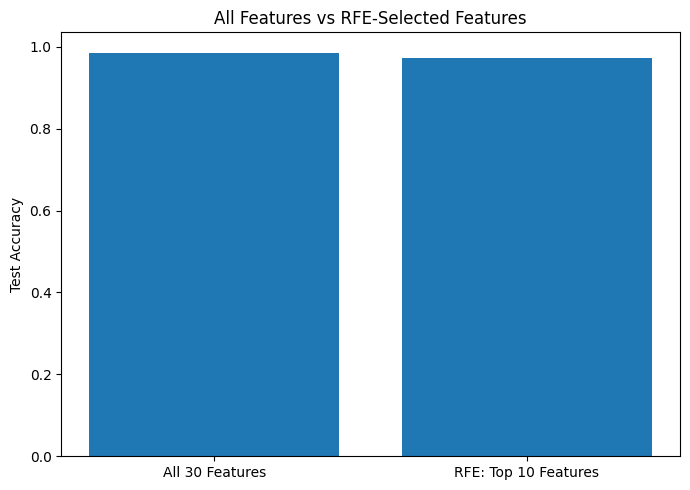

In [9]:
plt.figure(figsize=(7,5))
plt.bar(comparison["Model"], comparison["Test Accuracy"])
plt.ylabel("Test Accuracy")
plt.title("All Features vs RFE-Selected Features")
plt.tight_layout()
plt.show()


## 8. RFECV — let cross-validation choose feature count

Instead of manually choosing 10, RFECV tests different feature counts using cross-validation.

In [10]:
rfecv = RFECV(
    estimator=LogisticRegression(max_iter=3000),
    step=1,
    cv=5,
    scoring="accuracy",
    min_features_to_select=2
)

rfecv.fit(X_train_scaled, y_train)

print("Optimal number of features:", rfecv.n_features_)

rfecv_features = X.columns[rfecv.support_]

print("\nSelected features:")
for feature in rfecv_features:
    print("-", feature)


Optimal number of features: 14

Selected features:
- mean radius
- mean area
- mean concave points
- radius error
- area error
- compactness error
- worst radius
- worst texture
- worst perimeter
- worst area
- worst smoothness
- worst concavity
- worst concave points
- worst symmetry


## 9. Visualize RFECV performance

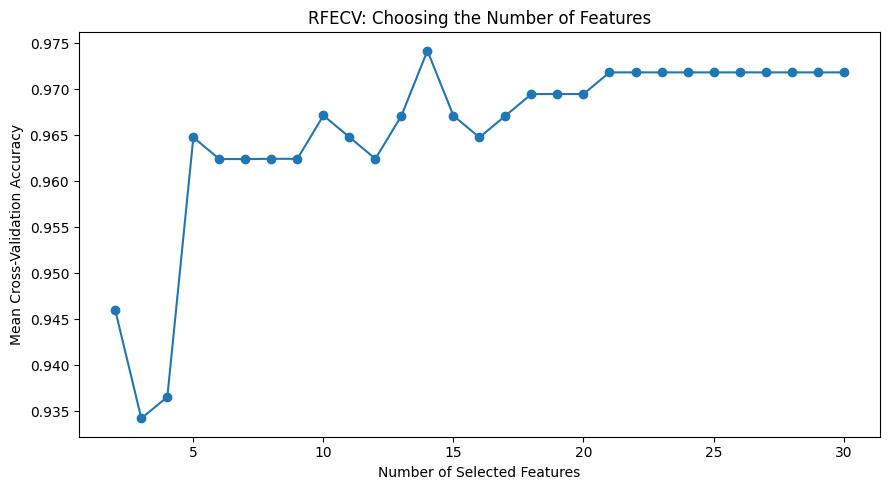

In [11]:
cv_results = rfecv.cv_results_

plt.figure(figsize=(9,5))
plt.plot(
    cv_results["n_features"],
    cv_results["mean_test_score"],
    marker="o"
)
plt.xlabel("Number of Selected Features")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.title("RFECV: Choosing the Number of Features")
plt.tight_layout()
plt.show()


## 10. SelectKBest vs RFE

**SelectKBest** is a filter method: fast, statistical, model-independent.

**RFE** is a wrapper method: model-aware, iterative, and more computationally expensive.

## Enterprise intuition

If a production model uses 200 features but similar performance is possible with 40, that can mean lower latency, simpler pipelines, lower feature-store cost, fewer data dependencies, easier monitoring, and easier explanations.

Feature selection can therefore be a systems-design decision too.

## Important caution

RFE depends on the estimator used inside it. Logistic Regression may choose a different subset from a tree-based model. Correlated features can also make rankings unstable.

Feature selection should stay inside the training/CV workflow to avoid leakage.

## What does this teach?

- RFE is a wrapper-based feature-selection method.
- It repeatedly removes the weakest features.
- The underlying model determines feature importance.
- Rank 1 means a feature is selected.
- RFECV chooses the number of features with cross-validation.
- RFE can be expensive for very high-dimensional data.

> **RFE asks the model: if I must remove one feature, which one can I afford to lose first?**

## References

- https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html
- https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFECV.html
- https://scikit-learn.org/stable/modules/feature_selection.html